¡Hola, Laura!

Mi nombre es Tonatiuh Cruz. Me complace revisar tu proyecto hoy.

Al identificar cualquier error inicialmente, simplemente los destacaré. Te animo a localizar y abordar los problemas de forma independiente como parte de tu preparación para un rol como data-analyst. En un entorno profesional, tu líder de equipo seguiría un enfoque similar. Si encuentras la tarea desafiante, proporcionaré una pista más específica en la próxima iteración.
Encontrarás mis comentarios a continuación - **por favor no los muevas, modifiques o elimines**.

Puedes encontrar mis comentarios en cajas verdes, amarillas o rojas como esta:

<div class="alert alert-block alert-success">
<b>Comentario del revisor</b> <a class="tocSkip"></a>

Éxito. Todo está hecho correctamente.
</div>

<div class="alert alert-block alert-warning">
<b>Comentario del revisor</b> <a class="tocSkip"></a>

Observaciones. Algunas recomendaciones.
</div>

<div class="alert alert-block alert-danger">
<b>Comentario del revisor</b> <a class="tocSkip"></a>

Necesita corrección. El bloque requiere algunas correcciones. El trabajo no puede ser aceptado con comentarios en rojo.
</div>

Puedes responderme utilizando esto:

<div class="alert alert-block alert-info">
<b>Respuesta del estudiante.</b> <a class="tocSkip"></a>
</div>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

In [2]:
hypotheses = pd.read_csv('/datasets/hypotheses_us.csv')
orders = pd.read_csv('/datasets/orders_us.csv')
visits = pd.read_csv('/datasets/visits_us.csv')

In [3]:
print(hypotheses.head())
print(orders.head())
print(visits.head())

print(hypotheses.info())
print(orders.info())
print(visits.info())

           Hypothesis;Reach;Impact;Confidence;Effort
0  Add two new channels for attracting traffic. T...
1  Launch your own delivery service. This will sh...
2  Add product recommendation blocks to the store...
3  Change the category structure. This will incre...
4  Change the background color on the main page. ...
   transactionId   visitorId        date  revenue group
0     3667963787  3312258926  2019-08-15     30.4     B
1     2804400009  3642806036  2019-08-15     15.2     B
2     2961555356  4069496402  2019-08-15     10.2     A
3     3797467345  1196621759  2019-08-15    155.1     B
4     2282983706  2322279887  2019-08-15     40.5     B
         date group  visits
0  2019-08-01     A     719
1  2019-08-02     A     619
2  2019-08-03     A     507
3  2019-08-04     A     717
4  2019-08-05     A     756
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 1 columns):
 #   Column                                     Non-Null Count  Dtype 
---  --

In [4]:
orders['date'] = pd.to_datetime(orders['date'])
visits['date'] = pd.to_datetime(visits['date'])

In [5]:
print(orders.duplicated().sum())
print(visits.duplicated().sum())

0
0


In [6]:
hypotheses = pd.read_csv('/datasets/hypotheses_us.csv', sep=';')

In [7]:
print(hypotheses.head())
print(hypotheses.info())

                                          Hypothesis  Reach  Impact  \
0  Add two new channels for attracting traffic. T...      3      10   
1  Launch your own delivery service. This will sh...      2       5   
2  Add product recommendation blocks to the store...      8       3   
3  Change the category structure. This will incre...      8       3   
4  Change the background color on the main page. ...      3       1   

   Confidence  Effort  
0           8       6  
1           4      10  
2           7       3  
3           3       8  
4           1       1  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Hypothesis  9 non-null      object
 1   Reach       9 non-null      int64 
 2   Impact      9 non-null      int64 
 3   Confidence  9 non-null      int64 
 4   Effort      9 non-null      int64 
dtypes: int64(4), object(1)
memory usage: 488.0+ 

## Parte 1 Priorizar hipotesis


In [8]:
#se calcula ICE
hypotheses['ICE'] = (hypotheses['Impact'] * hypotheses['Confidence']) / hypotheses['Effort']

In [9]:
#ordenar por ICE
ice_sorted = hypotheses.sort_values(by='ICE', ascending=False)

print(ice_sorted[['Hypothesis', 'ICE']])

                                          Hypothesis        ICE
8  Launch a promotion that gives users discounts ...  16.200000
0  Add two new channels for attracting traffic. T...  13.333333
7  Add a subscription form to all the main pages....  11.200000
6  Show banners with current offers and sales on ...   8.000000
2  Add product recommendation blocks to the store...   7.000000
1  Launch your own delivery service. This will sh...   2.000000
5  Add a customer review page. This will increase...   1.333333
3  Change the category structure. This will incre...   1.125000
4  Change the background color on the main page. ...   1.000000


In [10]:
#Calcular y ordenar por RICE
hypotheses['RICE'] = (hypotheses['Reach'] * hypotheses['Impact'] * hypotheses['Confidence']) / hypotheses['Effort']

rice_sorted = hypotheses.sort_values(by='RICE', ascending=False)

print(rice_sorted[['Hypothesis', 'RICE']])

                                          Hypothesis   RICE
7  Add a subscription form to all the main pages....  112.0
2  Add product recommendation blocks to the store...   56.0
0  Add two new channels for attracting traffic. T...   40.0
6  Show banners with current offers and sales on ...   40.0
8  Launch a promotion that gives users discounts ...   16.2
3  Change the category structure. This will incre...    9.0
1  Launch your own delivery service. This will sh...    4.0
5  Add a customer review page. This will increase...    4.0
4  Change the background color on the main page. ...    3.0


In [11]:
#Comparacion entre ICE Y RICE

ice_sorted['ICE_rank'] = range(1, len(ice_sorted) + 1)
rice_sorted['RICE_rank'] = range(1, len(rice_sorted) + 1)

comparison = ice_sorted[['Hypothesis', 'ICE', 'ICE_rank']].merge(
    rice_sorted[['Hypothesis', 'RICE', 'RICE_rank']],
    on='Hypothesis'
)

comparison['rank_diff'] = comparison['ICE_rank'] - comparison['RICE_rank']

print(comparison.sort_values(by='RICE_rank'))

                                          Hypothesis        ICE  ICE_rank  \
2  Add a subscription form to all the main pages....  11.200000         3   
4  Add product recommendation blocks to the store...   7.000000         5   
1  Add two new channels for attracting traffic. T...  13.333333         2   
3  Show banners with current offers and sales on ...   8.000000         4   
0  Launch a promotion that gives users discounts ...  16.200000         1   
7  Change the category structure. This will incre...   1.125000         8   
5  Launch your own delivery service. This will sh...   2.000000         6   
6  Add a customer review page. This will increase...   1.333333         7   
8  Change the background color on the main page. ...   1.000000         9   

    RICE  RICE_rank  rank_diff  
2  112.0          1          2  
4   56.0          2          3  
1   40.0          3         -1  
3   40.0          4          0  
0   16.2          5         -4  
7    9.0          6          2 

#El uso de RICE cambia la priorización porque introduce el factor Reach, lo que permite identificar las hipótesis que impactan a más usuarios.
En este caso:
ICE prioriza impacto inmediato
RICE prioriza impacto a escala
Por lo tanto, RICE es más adecuado para tomar decisiones estratégicas, ya que maximiza el impacto total en los ingresos.

<div class="alert alert-block alert-success">
<b>Comentario del revisor</b> <a class="tocSkip"></a>

Perfecto, Laura. Excelente trabajo aplicando, analizando y comparando los frameworks RICE e ICE. Solamente para complementar puedes hacer un análisis de los hallazgos para la priorización de las hipótesis.  </div>

## Parte 2 Analisis del test A/B

In [12]:
# Preparo datos
#convierto fechas 
orders['date'] = pd.to_datetime(orders['date'])
visits['date'] = pd.to_datetime(visits['date'])

In [13]:
#se eliminan usuarios en ambos grupos

group_counts = orders.groupby('visitorId')['group'].nunique()
bad_users = group_counts[group_counts > 1].index

orders = orders[~orders['visitorId'].isin(bad_users)]

In [14]:
# crear datos acumulados

orders_agg = orders.groupby(['date','group']).agg({
    'revenue':'sum'
}).reset_index()

orders_agg['cum_revenue'] = orders_agg.groupby('group')['revenue'].cumsum()

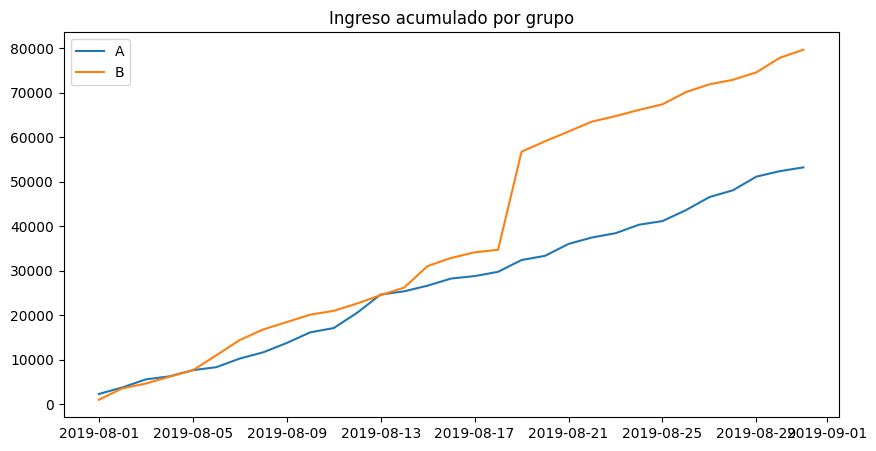

In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))

for group in orders_agg['group'].unique():
    data = orders_agg[orders_agg['group'] == group]
    plt.plot(data['date'], data['cum_revenue'], label=group)

plt.legend()
plt.title('Ingreso acumulado por grupo')
plt.show()

<div class="alert alert-block alert-success">
<b>Comentario del revisor</b> <a class="tocSkip"></a>

Perfecto, gran trabajo con el desarrollo y análisis del gráfico del tamaña de pedido acumulado por grupos. Ya solamente para complementar puedes realizar el ingreso acumulado desagregado por cada grupo

observamos como el ingreso acumulado del grupo B es similar al del grupo A pero aproximadamente desde el 18/08/2019 se evidencia un aumento baste notable del grupo B con respecto algrupo A

In [16]:
# Tamaño promedio de pedido acumulado
#Calcular AOV acumulado

orders_agg = orders.groupby(['date','group']).agg({
    'revenue':'sum',
    'transactionId':'nunique'
}).reset_index()

orders_agg['cum_revenue'] = orders_agg.groupby('group')['revenue'].cumsum()
orders_agg['cum_orders'] = orders_agg.groupby('group')['transactionId'].cumsum()

orders_agg['cum_aov'] = orders_agg['cum_revenue'] / orders_agg['cum_orders']

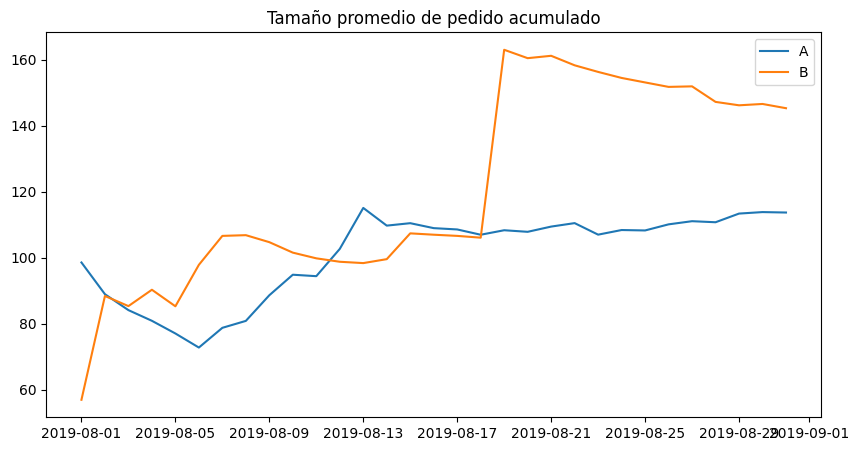

In [17]:
plt.figure(figsize=(10,5))

for group in orders_agg['group'].unique():
    data = orders_agg[orders_agg['group'] == group]
    plt.plot(data['date'], data['cum_aov'], label=group)

plt.legend()
plt.title('Tamaño promedio de pedido acumulado')
plt.show()

con respecto al tamano premedio se evidencia el alza del grupo B sobre el grupo A especialmente desde el 17 de agosto observandose un difenrecia considerablemente notable

In [18]:
#3.Diferencia relativa (B vs A)

merged = orders_agg.pivot(index='date', columns='group', values='cum_aov').reset_index()

merged['relative_diff'] = (merged['B'] / merged['A']) - 1

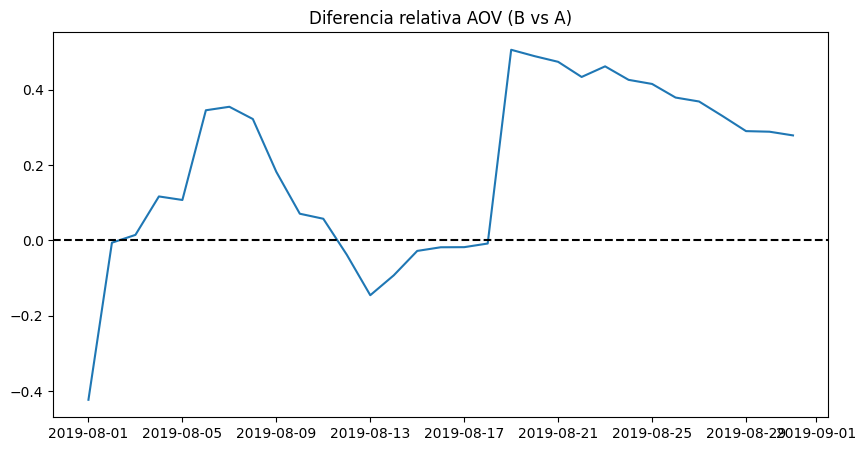

In [19]:
plt.figure(figsize=(10,5))

plt.plot(merged['date'], merged['relative_diff'])

plt.axhline(y=0, color='black', linestyle='--')
plt.title('Diferencia relativa AOV (B vs A)')
plt.show()

In [20]:
#4.  tasa de conversion
#pedidos por dia

orders_daily = orders.groupby(['date','group']).agg({
    'transactionId':'nunique'
}).reset_index()

orders_daily.rename(columns={'transactionId':'orders'}, inplace=True)


#unir con visitas

data = pd.merge(orders_daily, visits, on=['date','group'])

#calcular conversion

data['conversion'] = data['orders'] / data['visits']

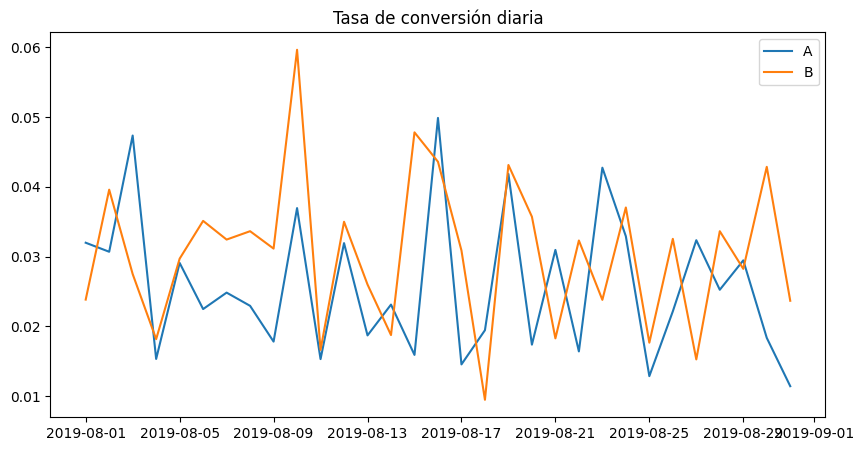

In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))

for group in data['group'].unique():
    subset = data[data['group'] == group]
    plt.plot(subset['date'], subset['conversion'], label=group)

plt.legend()
plt.title('Tasa de conversión diaria')
plt.show()

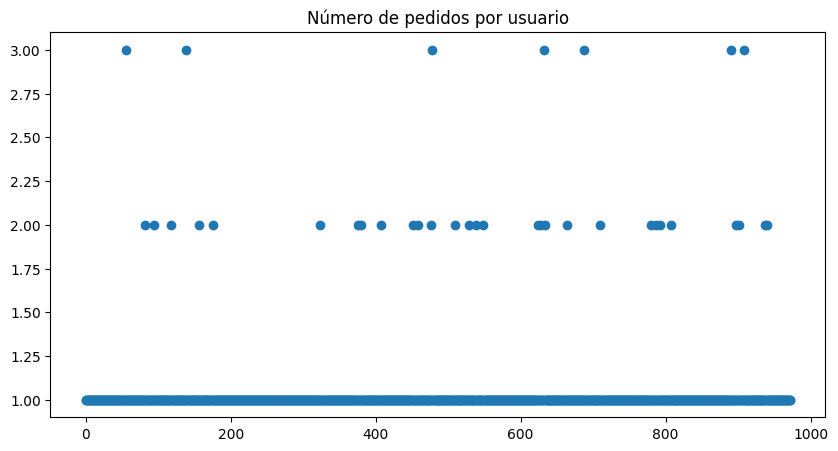

In [22]:
# grafico de dispersion del numero de pedidos por usuario

#calcular pedidos x usuarios
orders_per_user = orders.groupby('visitorId').agg({
    'transactionId':'nunique'
}).reset_index()

orders_per_user.columns = ['visitorId', 'orders']

plt.figure(figsize=(10,5))

plt.scatter(range(len(orders_per_user)), orders_per_user['orders'])

plt.title('Número de pedidos por usuario')
plt.show()

<div class="alert alert-block alert-success">
<b>Comentario del revisor</b> <a class="tocSkip"></a>

Excelente, buen trabajo con el grafico desplegado para estudiar la distribución del numero de pedidos por cliente.

se observa una línea muy densa en y = 1
Esto significa que la mayoría de los usuarios realiza solo una compra, La mayoría de los usuarios hace 1 compra; pocos hacen 2 o 3. Los valores superiores a 2 pueden considerarse atípicos.

In [23]:
# percentiles 95 y 99

import numpy as np

print(np.percentile(orders_per_user['orders'], [95, 99]))

[1. 2.]


La distribución del número de pedidos por usuario muestra que la gran mayoría de los usuarios realiza muy pocas compras. El 95% de los usuarios realiza hasta 1 pedido, y el 99% hasta 2 pedidos.

Esto indica que el comportamiento típico es de compras únicas, y que los usuarios con más de 2 pedidos son muy poco frecuentes. Por lo tanto, se pueden considerar como valores atípicos (outliers) aquellos usuarios que realizan más de 2 pedidos.

Estos outliers pueden influir en el análisis del test A/B, por lo que es recomendable tenerlos en cuenta o analizarlos por separado para obtener conclusiones más precisas.

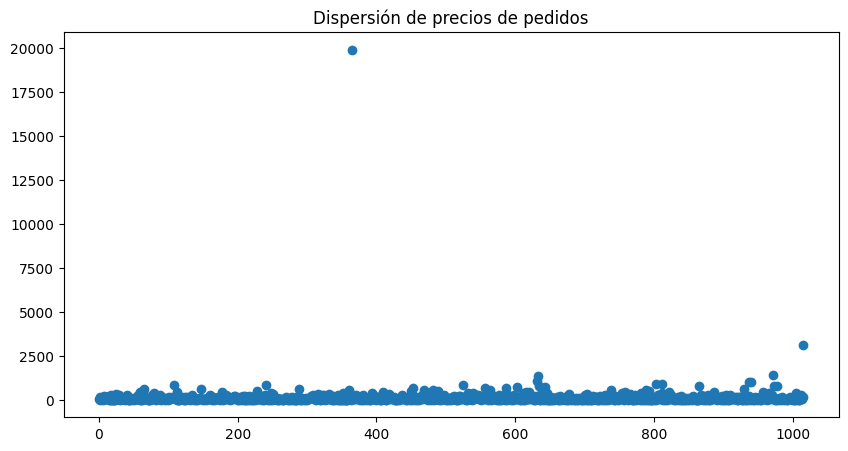

In [24]:
# Grafico de dispersion de los precios de los pedidos

plt.figure(figsize=(10,5))

plt.scatter(range(len(orders)), orders['revenue'])

plt.title('Dispersión de precios de pedidos')
plt.show()

La mayoría de los pedidos tiene valores bajos, pero existen algunos pedidos con valores significativamente altos. Estos valores extremos pueden considerarse outliers, ya que se alejan del comportamiento general y pueden distorsionar el análisis.

In [25]:
#Percentiles 95 y 99 (revenue)

import numpy as np

print(np.percentile(orders['revenue'], [95, 99]))

[414.275 830.3  ]


El 95% de los pedidos tiene un valor inferior a 414.275, y el 99% inferior a 830.3.

La mayoría de los pedidos se concentra por debajo del percentil 95. Los pedidos por encima de este valor pueden considerarse inusuales, mientras que aquellos por encima del percentil 99 pueden clasificarse como outliers y podrían afectar el análisis.

In [26]:
# significancia estadistica

#preparar datos
orders_by_user = orders.groupby(['visitorId','group']).agg({
    'transactionId':'nunique'
}).reset_index()

orders_by_user.columns = ['visitorId','group','orders']

#separar grupos
group_A = orders_by_user[orders_by_user['group']=='A']['orders']
group_B = orders_by_user[orders_by_user['group']=='B']['orders']

In [27]:
#Test Mann-Whitney

from scipy import stats

result = stats.mannwhitneyu(group_A, group_B)

print("p-value:", result.pvalue)

p-value: 0.5880266909361814


In [28]:
#diferencia relativa

print("Diferencia relativa:", group_B.mean() / group_A.mean() - 1)

Diferencia relativa: -0.013128075628075608


Si p < 0.05:

Existe una diferencia estadísticamente significativa en la tasa de conversión entre los grupos. Esto indica que uno de los grupos tiene un mejor desempeño y el cambio aplicado tiene un efecto real.

Si p > 0.05:

No se encontró una diferencia estadísticamente significativa en la tasa de conversión entre los grupos. Esto sugiere que el cambio no tiene un impacto claro en el comportamiento de los usuarios.

No se encontró una diferencia estadísticamente significativa en la tasa de conversión entre los grupos A y B, ya que el p-value (0.588) es mayor que el nivel de significancia de 0.05.

Además, la diferencia relativa en la conversión es de aproximadamente -1.31%, lo que indica que el grupo B presenta una conversión ligeramente menor que el grupo A. Sin embargo, esta diferencia es muy pequeña y no es estadísticamente significativa.

En consecuencia, no hay evidencia suficiente para afirmar que el cambio implementado en el grupo B tenga un impacto real en la conversión de los usuarios.

In [29]:
#10.Significancia del tamaño promedio de pedido (datos en bruto)
#preparar datos
rev_A = orders[orders['group']=='A']['revenue']
rev_B = orders[orders['group']=='B']['revenue']

from scipy import stats

result = stats.mannwhitneyu(rev_A, rev_B)

print("p-value:", result.pvalue)
print("Diferencia relativa:", rev_B.mean() / rev_A.mean() - 1)

p-value: 0.8622329690015668
Diferencia relativa: 0.27834487693078414


Si p > 0.05:
No hay diferencia significativa en el tamaño promedio de pedido entre los grupos.

Si p < 0.05:
Sí hay diferencia significativa.

In [30]:
#2 #filtrar usuarios anomalos

orders_per_user = orders.groupby('visitorId')['transactionId'].nunique()

abnormal_users = orders_per_user[orders_per_user > 2].index

filtered_orders = orders[~orders['visitorId'].isin(abnormal_users)]

In [31]:
#conversion con datos filtrados

orders_by_user = filtered_orders.groupby(['visitorId','group']).agg({
    'transactionId':'nunique'
}).reset_index()

orders_by_user.columns = ['visitorId','group','orders']

#separar grupos
group_A = orders_by_user[orders_by_user['group']=='A']['orders']
group_B = orders_by_user[orders_by_user['group']=='B']['orders']

#test estadistico

result = stats.mannwhitneyu(group_A, group_B)

print("p-value:", result.pvalue)
print("Diferencia relativa:", group_B.mean() / group_A.mean() - 1)

p-value: 0.93724284674733
Diferencia relativa: 0.000847749267662179


In [32]:
#tamano promedio con datos filtrados
rev_A_f = filtered_orders[filtered_orders['group']=='A']['revenue']
rev_B_f = filtered_orders[filtered_orders['group']=='B']['revenue']

result = stats.mannwhitneyu(rev_A_f, rev_B_f)

print("p-value:", result.pvalue)
print("Diferencia relativa:", rev_B_f.mean() / rev_A_f.mean() - 1)

p-value: 0.7486354077095634
Diferencia relativa: 0.27893080140809734


<div class="alert alert-block alert-success">
<b>Comentario del revisor</b> <a class="tocSkip"></a>



Excelente trabajo con el desarrollo de esta sección donde hacemos las pruebas estadística con la diferencia de medias </div>

p-value (lo más importante)
Como 0.748 > 0.05:
NO hay diferencia estadísticamente significativa

Diferencia relativa (+27.89%)
Esto significa que:

El grupo B tiene un tamaño promedio de pedido ~28% mayor que A
PERO
Como no es significativa, esto implica:
Esa diferencia puede estar causada por outliers o variabilidad

Resumen de tus resultados
Conversión (datos en bruto): no significativa (p = 0.588)
Tamaño promedio (datos en bruto): no significativo (p = 0.748)
Diferencias observadas → pueden estar influenciadas por outliers
No hay evidencia consistente de que el grupo B sea mejor

Decisión final
Opción 2: Parar la prueba, concluir que no hay diferencia entre los grupos

Con base en los resultados del análisis del test A/B, se recomienda detener la prueba y concluir que no existe una diferencia estadísticamente significativa entre los grupos A y B.

Las métricas clave, como la tasa de conversión y el tamaño promedio de pedido, no muestran diferencias significativas, ya que los valores p obtenidos son mayores que 0.05. Aunque en algunos casos se observan diferencias en los valores promedio, estas no son estadísticamente confiables y pueden estar influenciadas por valores atípicos.

Por lo tanto, no hay evidencia suficiente para afirmar que la variante B genere una mejora en el desempeño, y no se recomienda su implementación.